### Langchain Version V1

### Basic Agent

In [128]:
import langchain    
langchain.__version__

'1.4.3'

In [156]:
import os
from dotenv import load_dotenv 
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GEMINI_API_KEY"] = os.getenv("GEMINI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["OPENROUTER_API_KEY"] = os.getenv("OPENROUTER_API_KEY")
    

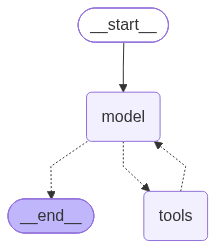

In [110]:
from langchain.agents import create_agent

def get_weather(city):
    """Get the current weather for a given city."""
    return f"The current weather in {city} is cloudy with a temperature."

agent=create_agent(
    model = "openrouter:nvidia/nemotron-3-ultra-550b-a55b:free", # specify the model with collan
    # model_provider="openai", gives error
    tools = [get_weather],
    system_prompt="You are a helpful assistant"
)
agent

In [121]:
### Run the agent
response=agent.invoke({"messages": 
              [{"role": "user", "content": "What is the weather in New York?"}]})

In [122]:
response["messages"][-1].content

'The current weather in New York is cloudy with a temperature.'

In [ ]:
agent.invoke({"messages": [{"role": "user", "content": "What is the weather in abbottabad"}]})

{'messages': [HumanMessage(content='What is the weather in abbottabad', additional_kwargs={}, response_metadata={}, id='bc563164-0625-42dd-b502-228d9971aa88'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user is asking for the weather in Abbottabad. I need to use the get_weather tool with city parameter "Abbottabad". Let\'s call the function.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user is asking for the weather in Abbottabad. I need to use the get_weather tool with city parameter "Abbottabad". Let\'s call the function.'}]}, response_metadata={'model_name': 'nvidia/nemotron-3-ultra-550b-a55b:free', 'id': 'gen-1790768124-brBqW1zXN7vikmELqb0N', 'created': 1790768124, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'upstream_inference_prompt_cost': 0.0, 'upstream_inference_c

### Google-gemini Weather Check

In [ ]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent

# Load API keys
load_dotenv()
os.environ["GEMINI_API_KEY"] = os.getenv("GEMINI_API_KEY")

# Define a simple tool
def get_weather(city: str):
    """Get the current weather for a given city."""
    return f"The current weather in {city} is cloudy with a temperature."

# Initialize Groq model
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",   # ✅ valid Groq model
    google_api_key=os.getenv("GEMINI_API_KEY")
)

# Create agent
agent = create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are a helpful assistant"
)

# Run the agent
response = agent.invoke({
    "messages": [{"role": "user", "content": "What is the weather in New York?"}]
})
print(response)


{'messages': [HumanMessage(content='What is the weather in New York?', additional_kwargs={}, response_metadata={}, id='8777af5a-e0e4-4569-957f-0b0c6a6d3f64'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"city": "New York"}'}, '__gemini_function_call_thought_signatures__': {'call_611032': 'EvkBCvYBAWkUfRMCggG7ZCZyLCd0loxDTOnYdlzOub/Vv+50R8o7XzHTEPOSVpAv/hM+KugBlmGEjdjK8lQAvfhzX01s50hCJ+TJ++cXHXhUz2/5w4R+kkqV68s4XXl5ANGbMSuiOyYrVR5XFd15fHsnHySG0MAwyB2hFvksLNarX7Rz487Wy2R+ZmJ3gjWtFzv/MZMtSZh4f0WxKZ6ZbJDCQRw9Ai/4OkAaqkcw3gDQCuMAJsx7Yo8P/T/u1wDrR4RD0w9aH7IqhkHcsBvWrxcMPiN8BHVVMu7d5hXNbeHQ6MLFqb0oXPSBdMPmZP+EKKboiQvqFZTlIbU3'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a0f1f7-a7c9-70c2-8af0-e6c165a1466a-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'New York'}, 'id': 'call_611032', 'type': 'tool_call'}], invalid_tool_calls

### Google-gemini API Check

In [113]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

# Load variables from the .env file
load_dotenv()

# Initialize the free Gemini model
llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash")

# Invoke the model
response = llm.invoke("What is the distance between Earth and Mars?")
print(response.content)

[{'type': 'text', 'text': 'The distance between Earth and Mars is constantly changing because both planets travel around the Sun in elliptical orbits at different speeds. \n\nHere are the key distances:\n\n* **Average distance:** About **225 million km** (140 million miles)\n* **Closest approach (minimum distance):** Theoretically about **54.6 million km** (33.9 million miles). In recorded history, the closest recent approach occurred in 2003, when they were **55.7 million km** (34.6 million miles) apart.\n* **Farthest distance (maximum distance):** About **401 million km** (250 million miles), which happens when the two planets are on completely opposite sides of the Sun.\n\n### Why does it vary so much?\n* **Earth** takes 365 days to orbit the Sun, while **Mars** takes about 687 Earth days.\n* Every **26 months**, Earth catches up to and passes Mars (an event called *opposition*), bringing the two planets closest together. This 26-month window is when space agencies typically launch 

### Openrouter API Check

In [118]:
import os
from dotenv import load_dotenv
from langchain_openrouter import ChatOpenRouter

# Load variables from the .env file
load_dotenv()

# Initialize the free Gemini model
llm = ChatOpenRouter(model="nvidia/nemotron-3-ultra-550b-a55b:free", api_key=os.getenv("OPENROUTER_API_KEY"))

# Invoke the model
response = llm.invoke("What is the distance between Earth and Mars?")
print(response.content)

The distance between Earth and Mars **changes constantly** because both planets are orbiting the Sun at different speeds and distances.

Here are the key figures:

| Scenario | Distance | Details |
| :--- | :--- | :--- |
| **Closest Possible (Opposition/Perihelion)** | **~54.6 million km** (33.9 million miles) | Occurs when Earth passes Mars while Mars is at its closest point to the Sun (perihelion). This happens roughly every 15–17 years. |
| **Farthest Possible (Conjunction/Aphelion)** | **~401 million km** (249 million miles) | Occurs when the Sun is directly between Earth and Mars, and Mars is at its farthest point from the Sun (aphelion). |
| **Average Distance** | **~225 million km** (140 million miles) | The semi-major axis average over time. |

### Why does it vary so much?
1.  **Elliptical Orbits:** Neither planet orbits in a perfect circle. Mars has a notably eccentric (oval-shaped) orbit.
2.  **Orbital Periods:** Earth orbits the Sun in **365 days**; Mars takes **687 days**.

### Groq API Check

In [107]:

import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

# Load variables from the .env file
load_dotenv()

# Initialize the free Gemini model
llm = ChatGroq(model="openai/gpt-oss-safeguard-20b", api_key=os.getenv("GROQ_API_KEY"))

# Invoke the model
response = llm.invoke("What is the distance between Earth and Mars?")
print(response.content)

The distance between Earth and Mars isn’t a single fixed number—it changes constantly as the two planets orbit the Sun.  
Here’s a quick snapshot of the key figures:

| Situation | Approximate Distance |
|-----------|----------------------|
| **Closest approach (perihelic opposition)** | ~54 million km (≈0.36 AU) |
| **Farthest distance (opposition at aphelion)** | ~401 million km (≈2.7 AU) |
| **Average over a full orbit** | ~225 million km (≈1.5 AU) |

**Why the range?**  
- Earth’s orbit is nearly circular (eccentricity ~0.0167).  
- Mars’s orbit is more elliptical (eccentricity ~0.0934).  
- The two planets also have different orbital periods (Earth ≈ 365 days, Mars ≈ 687 days).  
Because of this, the distance swings between the extremes listed above every ~26 months (the synodic period of Mars).

**Quick reference:**  
- 1 Astronomical Unit (AU) ≈ 149.6 million km (average Earth–Sun distance).  
- Thus, at its closest, Mars is about 0.36 AU from Earth; at its farthest, about 2.7 A